### Notebook for elliptical-approach CCF data ($\tau_{max}$, $\tau_0$, $v_{pol}$, $v_{fade}$) visualization.

In [1]:
import flap
import flap_w7x_abes
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import h5py
import json

CORR_THRESHOLD = 0

mpl.rcParams.update({
    'font.size': 12
})

with open('../lcfs_pos.json', 'r') as f:
    lcfs_pos = json.load(f)

INIT flap storage
Importing flap_w7x_abes
Importing w7x_webapi


In [2]:
exp_id = '20250409.046'
r_lcfs = lcfs_pos[exp_id]
r_lcfs

6.25

Load the elliptical-model CCF data. On top of the Taylor quantities (`tau`, `corrs`,
`vpol`) this file also carries `tau_0` (fading timescale) and `vfade` (fading velocity),
per eqs. (2)-(3) of Krämer-Flecken et al. 2025.

In [3]:
with h5py.File(f'../processed_data/elliptical/{exp_id}/{exp_id}_elliptical.h5', 'r') as f:

    exp_id = f['ccf_data'].attrs['exp_id']
    udefl = f['ccf_data'].attrs['poloidal_deflection_voltage']
    deltay = f['ccf_data'].attrs['poloidal_separation']
    twindow = f['ccf_data'].attrs['ccf_window']
    intervaln = f['ccf_data'].attrs['ccf_interval_n']

    times = f['ccf_data/time_range'][:]
    channels = f['ccf_data/channels'][:]

    tau = f['ccf_data/ccf_max_time_lags'][:]
    tau_err = f['ccf_data/ccf_max_time_lag_err'][:]
    corrs = f['ccf_data/ccf_correlations'][:]

    tau0 = f['ccf_data/tau_0'][:]
    tau0_err = f['ccf_data/tau_0_err'][:]

    vpol = f['ccf_data/poloidal_velocity'][:]
    vpol_err = f['ccf_data/poloidal_velocity_err'][:]

    vfade = f['ccf_data/fading_velocity'][:]
    vfade_err = f['ccf_data/fading_velocity_err'][:]

### Spatial calibration

In [4]:
spatcal = flap_w7x_abes.ShotSpatCal(exp_id)
spatcal.read()
dev_r = np.array([
    spatcal.data['Device R'][spatcal.data['Channel name'] == f'ABES-{ch}'] for ch in np.arange(1, 41)
]).T[0]

In [5]:
min(dev_r), max(dev_r)

(np.float64(6.086611510145259), np.float64(6.305569997775299))

Filter out points where the CCF peak is below `CORR_THRESHOLD`: `tau_0` and the two
velocities are only meaningful where the correlation peak is a real feature and not noise.

In [6]:
def filtered(arr):
    out = arr.copy()
    out[corrs < CORR_THRESHOLD] = np.nan
    return out

tau_filtered = filtered(tau)
tau_err_filtered = filtered(tau_err)
tau0_filtered = filtered(tau0)
tau0_err_filtered = filtered(tau0_err)
vpol_filtered = filtered(vpol)
vpol_err_filtered = filtered(vpol_err)
vfade_filtered = filtered(vfade)
vfade_err_filtered = filtered(vfade_err)

### Plot CCF time lags and correlation

`tau` carries a sign (propagation direction), so it uses the diverging `bwr` colormap.
`corrs` is non-negative (normalized CCF, `xcorr_normalize=True`), so it uses `plasma`.

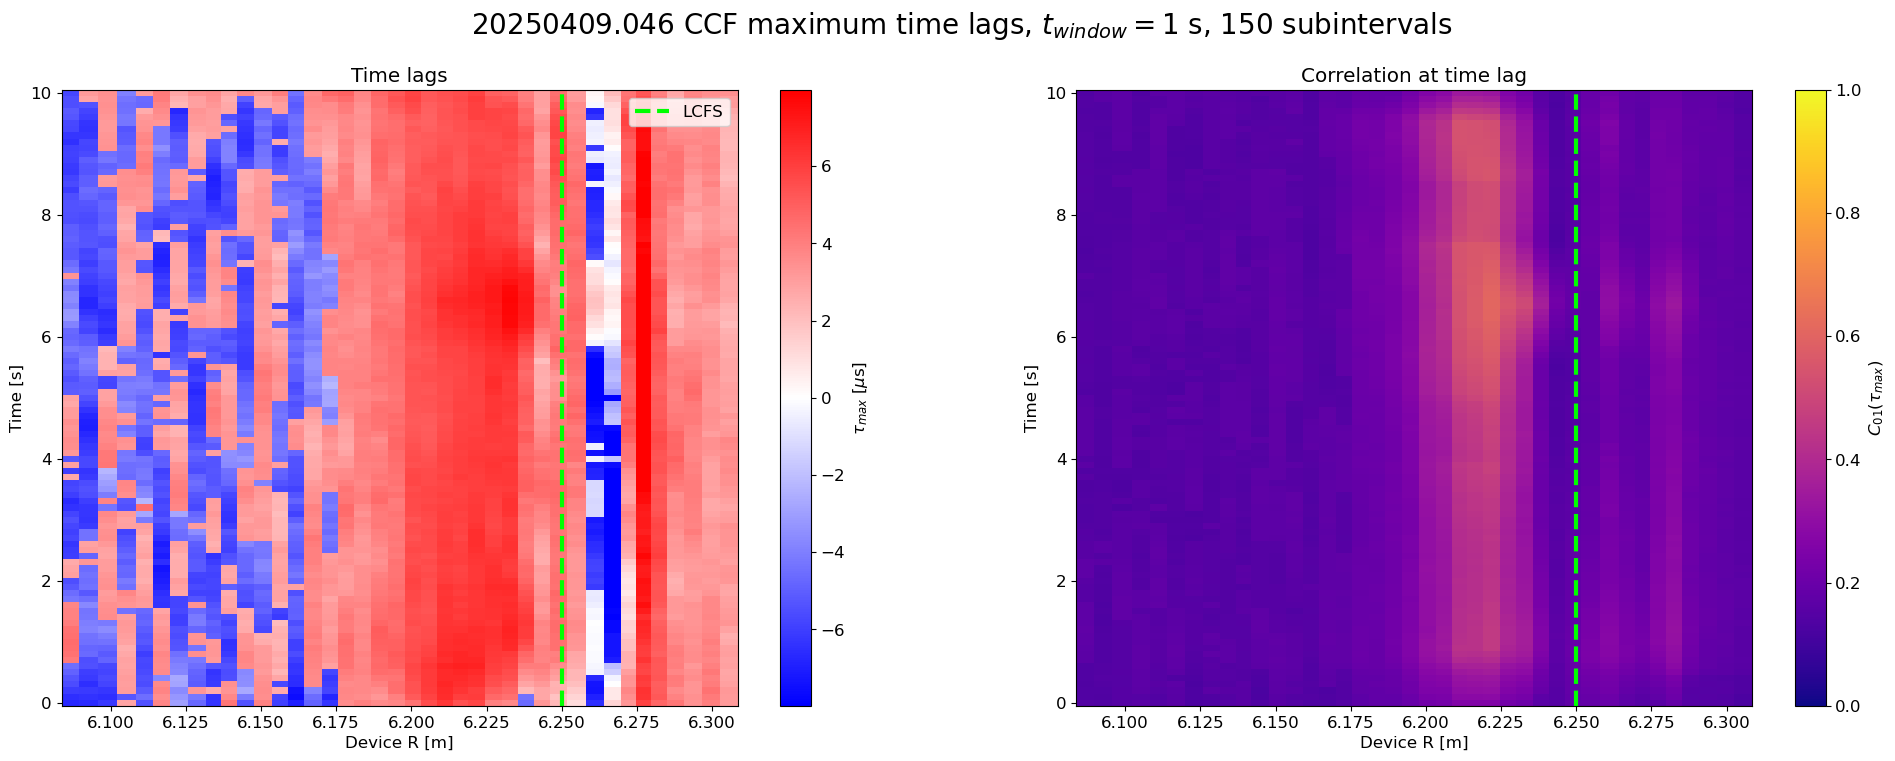

In [7]:
tau_absmax = np.nanpercentile(np.abs(tau_filtered), 98)

fig, ax = plt.subplots(figsize = (24, 8), nrows = 1, ncols = 2)
plt.suptitle(f'{exp_id} CCF maximum time lags, $t_{{window}} = {twindow}$ s, {intervaln} subintervals', fontsize = 20)

ax[0].set_title('Time lags')
ax[0].set_xlabel('Device R [m]')
ax[0].set_ylabel('Time [s]')
pc1 = ax[0].pcolormesh(dev_r, times, tau_filtered, cmap = 'bwr', vmin = -tau_absmax, vmax = tau_absmax, shading = 'nearest')
cbar1 = fig.colorbar(pc1, ax = ax[0])
cbar1.set_label('$\\tau_{max}$ [$\\mu$s]')

ax[1].set_title('Correlation at time lag')
ax[1].set_xlabel('Device R [m]')
ax[1].set_ylabel('Time [s]')
pc2 = ax[1].pcolormesh(dev_r, times, corrs, cmap = 'plasma', vmin = 0, vmax = 1, shading = 'nearest')
cbar2 = fig.colorbar(pc2, ax = ax[1])
cbar2.set_label('$C_{01}(\\tau_{max})$')

for a in ax:
    a.axvline(r_lcfs, c = 'lime', lw = 3, ls = '--', label = 'LCFS')

ax[0].legend()
# plt.savefig(f'../plots/{exp_id}/{exp_id}_ccf_corrs_elliptical.pdf')

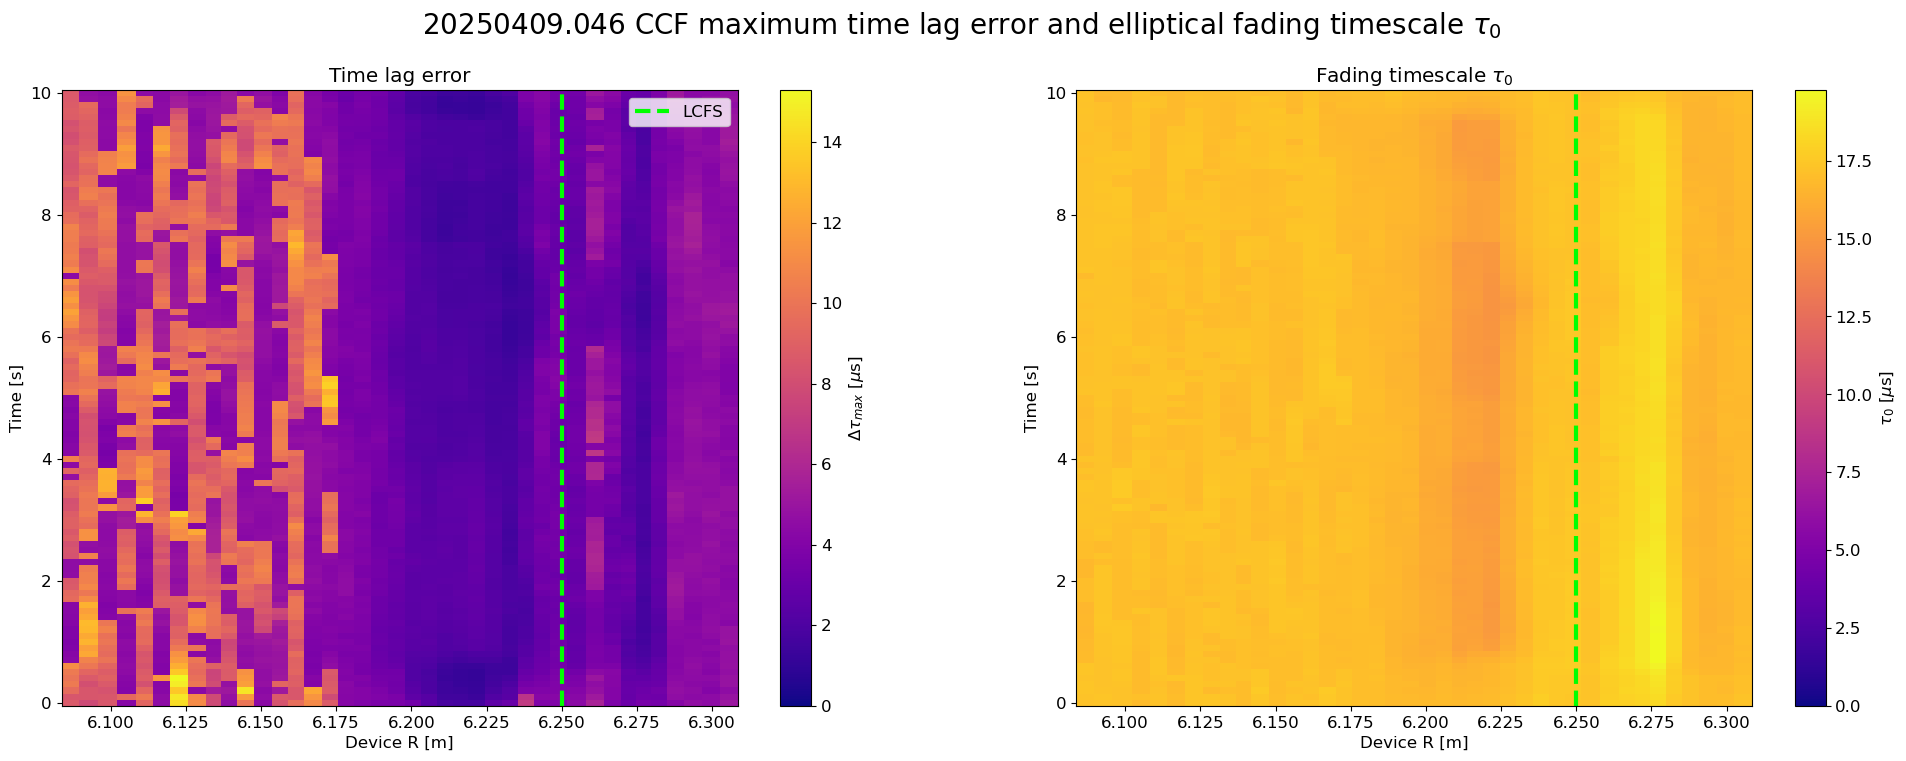

In [8]:
fig, ax = plt.subplots(figsize = (24, 8), nrows = 1, ncols = 2)
plt.suptitle(f'{exp_id} CCF maximum time lag error and elliptical fading timescale $\\tau_0$', fontsize = 20)

ax[0].set_title('Time lag error')
ax[0].set_xlabel('Device R [m]')
ax[0].set_ylabel('Time [s]')
pc1 = ax[0].pcolormesh(dev_r, times, tau_err_filtered, cmap = 'plasma', vmin = 0, shading = 'nearest')
cbar1 = fig.colorbar(pc1, ax = ax[0])
cbar1.set_label('$\\Delta\\tau_{max}$ [$\\mu$s]')

ax[1].set_title('Fading timescale $\\tau_0$')
ax[1].set_xlabel('Device R [m]')
ax[1].set_ylabel('Time [s]')
pc2 = ax[1].pcolormesh(dev_r, times, tau0_filtered, cmap = 'plasma', vmin = 0, shading = 'nearest')
cbar2 = fig.colorbar(pc2, ax = ax[1])
cbar2.set_label('$\\tau_0$ [$\\mu$s]')

for a in ax:
    a.axvline(r_lcfs, c = 'lime', lw = 3, ls = '--', label = 'LCFS')

ax[0].legend()
# plt.savefig(f'../plots/{exp_id}/{exp_id}_tau0.pdf')

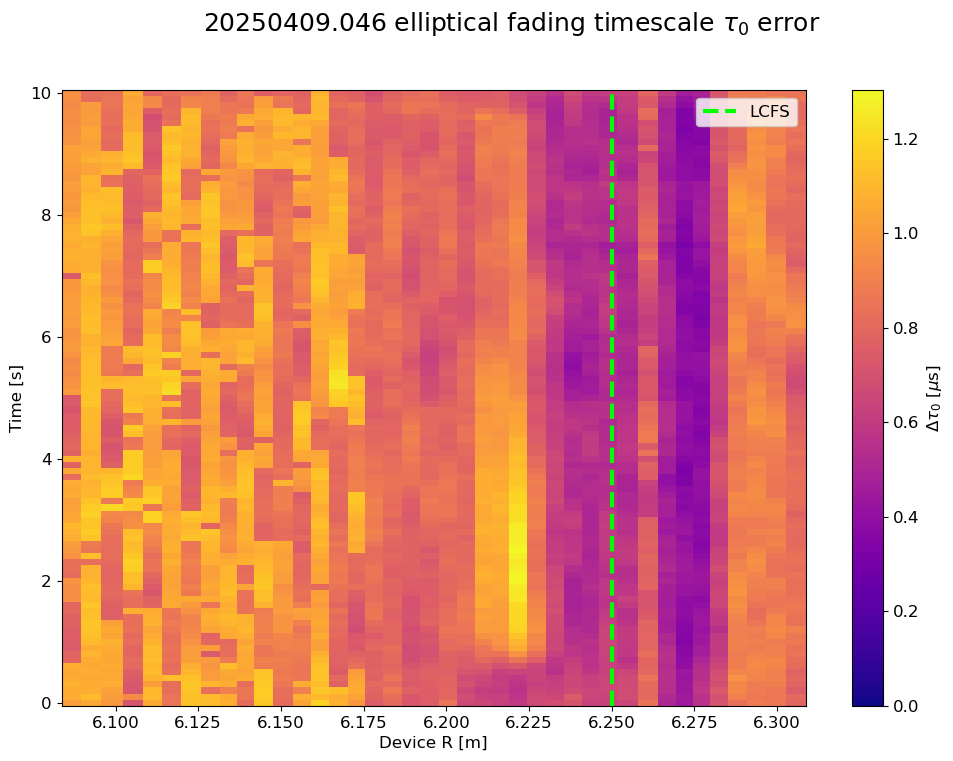

In [9]:
fig, ax = plt.subplots(figsize = (12, 8))
plt.suptitle(f'{exp_id} elliptical fading timescale $\\tau_0$ error', fontsize = 18)

ax.set_xlabel('Device R [m]')
ax.set_ylabel('Time [s]')
pc = ax.pcolormesh(dev_r, times, tau0_err_filtered, cmap = 'plasma', vmin = 0, shading = 'nearest')
cbar = fig.colorbar(pc, ax = ax)
cbar.set_label('$\\Delta\\tau_0$ [$\\mu$s]')

ax.axvline(r_lcfs, c = 'lime', lw = 3, ls = '--', label = 'LCFS')
ax.legend()
# plt.savefig(f'../plots/{exp_id}/{exp_id}_tau0_err.pdf')

### Plot poloidal velocity ($v_{pol}$, eq. 2)

Signed (propagation direction), so `bwr`. Its error is non-negative, so `plasma`.

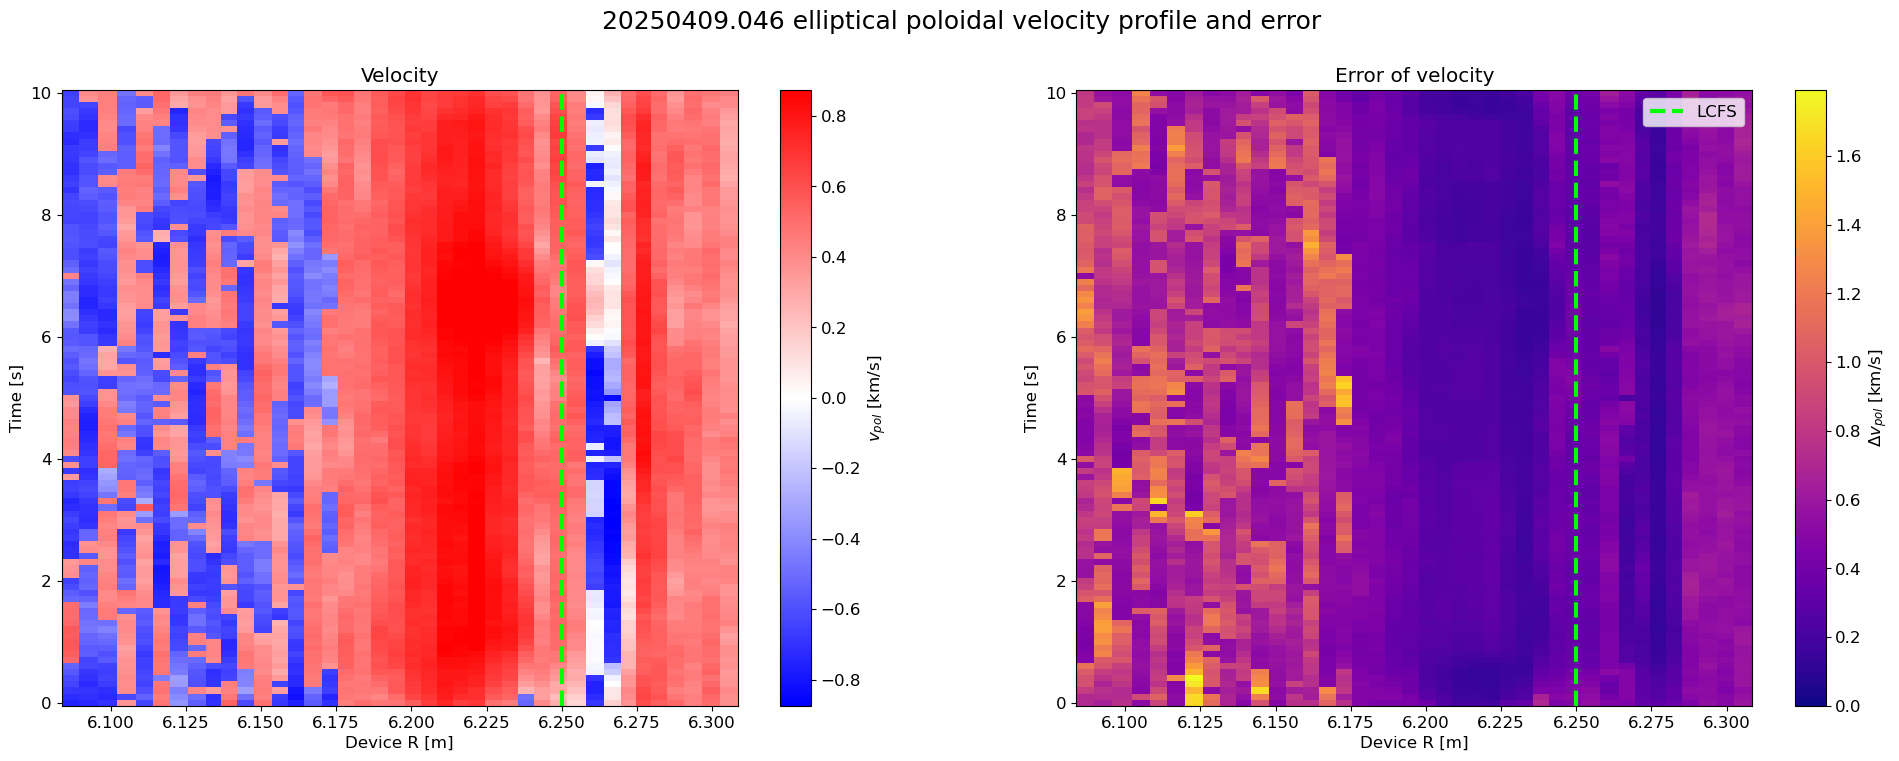

In [10]:
vpol_absmax = np.nanpercentile(np.abs(vpol_filtered), 98)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (24, 8))
plt.suptitle(f'{exp_id} elliptical poloidal velocity profile and error', fontsize = 18)

ax1.set_title('Velocity')
ax1.set_xlabel('Device R [m]')
ax1.set_ylabel('Time [s]')
pc1 = ax1.pcolormesh(dev_r, times, vpol_filtered, cmap = 'bwr', vmin = -vpol_absmax, vmax = vpol_absmax, shading = 'nearest')
cbar1 = fig.colorbar(pc1, ax = ax1)
cbar1.set_label('$v_{pol}$ [km/s]')

ax2.set_title('Error of velocity')
ax2.set_xlabel('Device R [m]')
ax2.set_ylabel('Time [s]')
pc2 = ax2.pcolormesh(dev_r, times, vpol_err_filtered, cmap = 'plasma', vmin = 0, shading = 'nearest')
cbar2 = fig.colorbar(pc2, ax = ax2)
cbar2.set_label('$\\Delta v_{pol}$ [km/s]')

for a in (ax1, ax2):
    a.axvline(r_lcfs, lw = 3, c = 'lime', ls = '--', label = 'LCFS')

ax2.legend()
# plt.savefig(f'../plots/{exp_id}/{exp_id}_vpol_elliptical.pdf')

### Plot fading velocity ($v_{fade}$, eq. 3)

Unlike $v_{pol}$, $v_{fade}$ carries no sign information since `dt` only enters it
squared (see `CorrelationAnalysis.get_velocity_elliptical`), so it is non-negative and
uses `plasma`, same as its error.

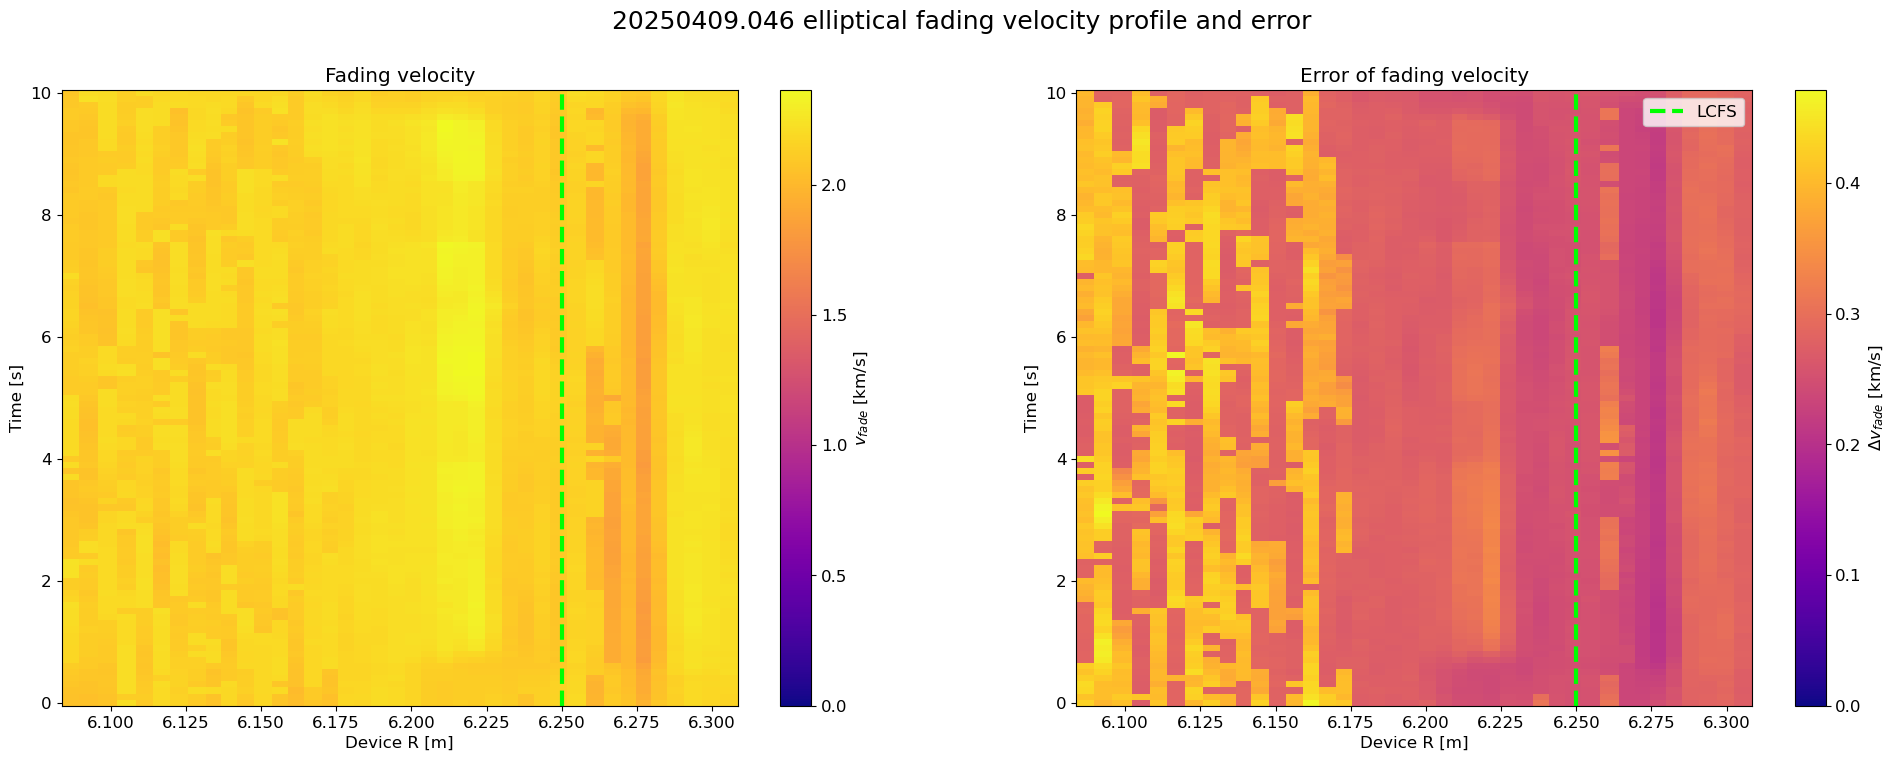

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (24, 8))
plt.suptitle(f'{exp_id} elliptical fading velocity profile and error', fontsize = 18)

ax1.set_title('Fading velocity')
ax1.set_xlabel('Device R [m]')
ax1.set_ylabel('Time [s]')
pc1 = ax1.pcolormesh(dev_r, times, vfade_filtered, cmap = 'plasma', vmin = 0, shading = 'nearest')
cbar1 = fig.colorbar(pc1, ax = ax1)
cbar1.set_label('$v_{fade}$ [km/s]')

ax2.set_title('Error of fading velocity')
ax2.set_xlabel('Device R [m]')
ax2.set_ylabel('Time [s]')
pc2 = ax2.pcolormesh(dev_r, times, vfade_err_filtered, cmap = 'plasma', vmin = 0, shading = 'nearest')
cbar2 = fig.colorbar(pc2, ax = ax2)
cbar2.set_label('$\\Delta v_{fade}$ [km/s]')

for a in (ax1, ax2):
    a.axvline(r_lcfs, lw = 3, c = 'lime', ls = '--', label = 'LCFS')

ax2.legend()
# plt.savefig(f'../plots/{exp_id}/{exp_id}_vfade_elliptical.pdf')

### Radial slices of $v_{pol}$ and $v_{fade}$

In [15]:
# Pick the time index with the most correlation-threshold-surviving channels
time_slice_idx = 20

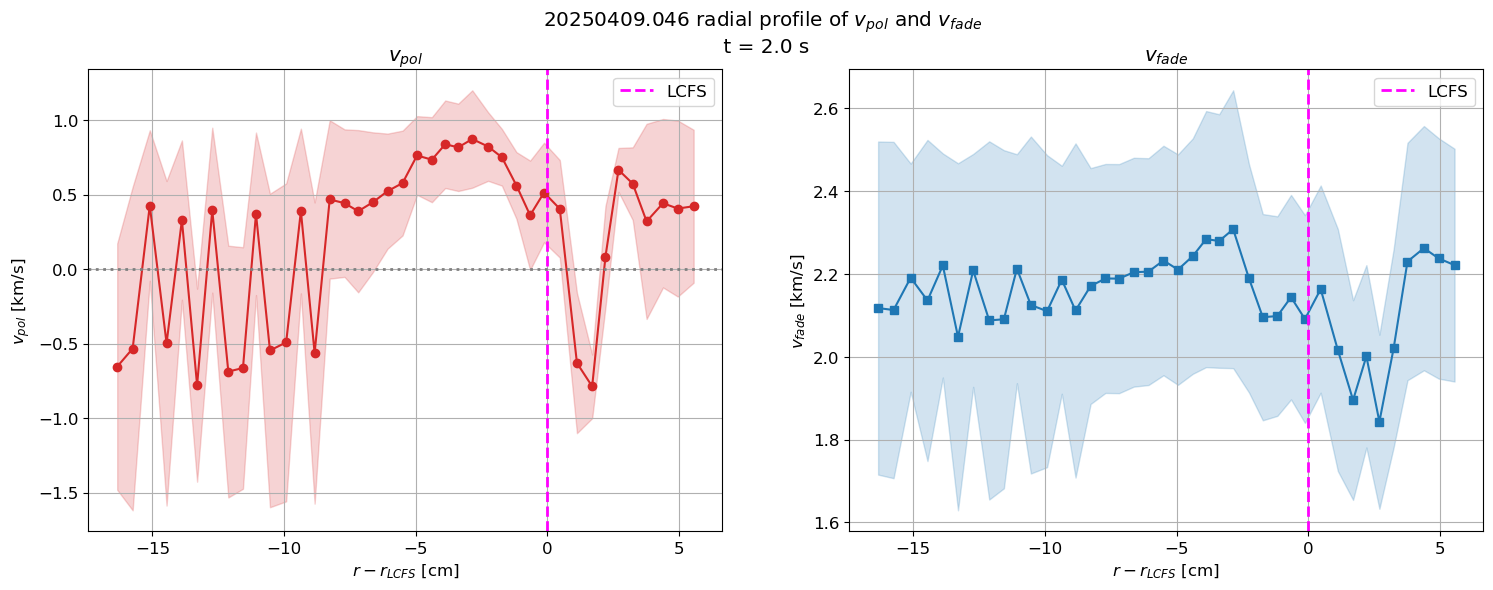

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (18, 6), sharex = True)

mask_v = ~np.isnan(vpol_filtered[time_slice_idx])
mask_f = ~np.isnan(vfade_filtered[time_slice_idx])

fig.suptitle(f'{exp_id} radial profile of $v_{{pol}}$ and $v_{{fade}}$ \n t = {times[time_slice_idx]} s')

ax1.set_title('$v_{pol}$')
ax2.set_title('$v_{fade}$')
ax1.set_xlabel('$r - r_{LCFS}$ [cm]')
ax2.set_xlabel('$r - r_{LCFS}$ [cm]')
ax1.set_ylabel('$v_{pol}$ [km/s]')
ax2.set_ylabel('$v_{fade}$ [km/s]')

r_rel = (dev_r - r_lcfs) * 100

ax1.plot(r_rel[mask_v], vpol_filtered[time_slice_idx, mask_v], marker = 'o', c = 'tab:red')
ax1.fill_between(r_rel[mask_v],
                  vpol_filtered[time_slice_idx, mask_v] - np.abs(vpol_err_filtered[time_slice_idx, mask_v]),
                  vpol_filtered[time_slice_idx, mask_v] + np.abs(vpol_err_filtered[time_slice_idx, mask_v]),
                  color = 'tab:red', alpha = 0.2)

ax2.plot(r_rel[mask_f], vfade_filtered[time_slice_idx, mask_f], marker = 's', c = 'tab:blue')
ax2.fill_between(r_rel[mask_f],
                  vfade_filtered[time_slice_idx, mask_f] - np.abs(vfade_err_filtered[time_slice_idx, mask_f]),
                  vfade_filtered[time_slice_idx, mask_f] + np.abs(vfade_err_filtered[time_slice_idx, mask_f]),
                  color = 'tab:blue', alpha = 0.2)

ax1.axhline(0, ls = 'dotted', c = 'grey', lw = 2)

for a in (ax1, ax2):
    a.axvline(0, c = 'magenta', ls = '--', lw = 2, label = 'LCFS')
    a.grid()
    a.legend()

# plt.savefig(f'../plots/{exp_id}/{exp_id}_vpol_vfade_radial_slice.pdf')

Same radial slice, split into two panels so each velocity keeps its own natural (signed
vs. non-negative) y-axis, and overlaid across a few neighbouring time points.

Text(0.5, 0.98, '20250409.046 radial profiles of $v_{pol}$ and $v_{fade}$ across neighbouring windows')

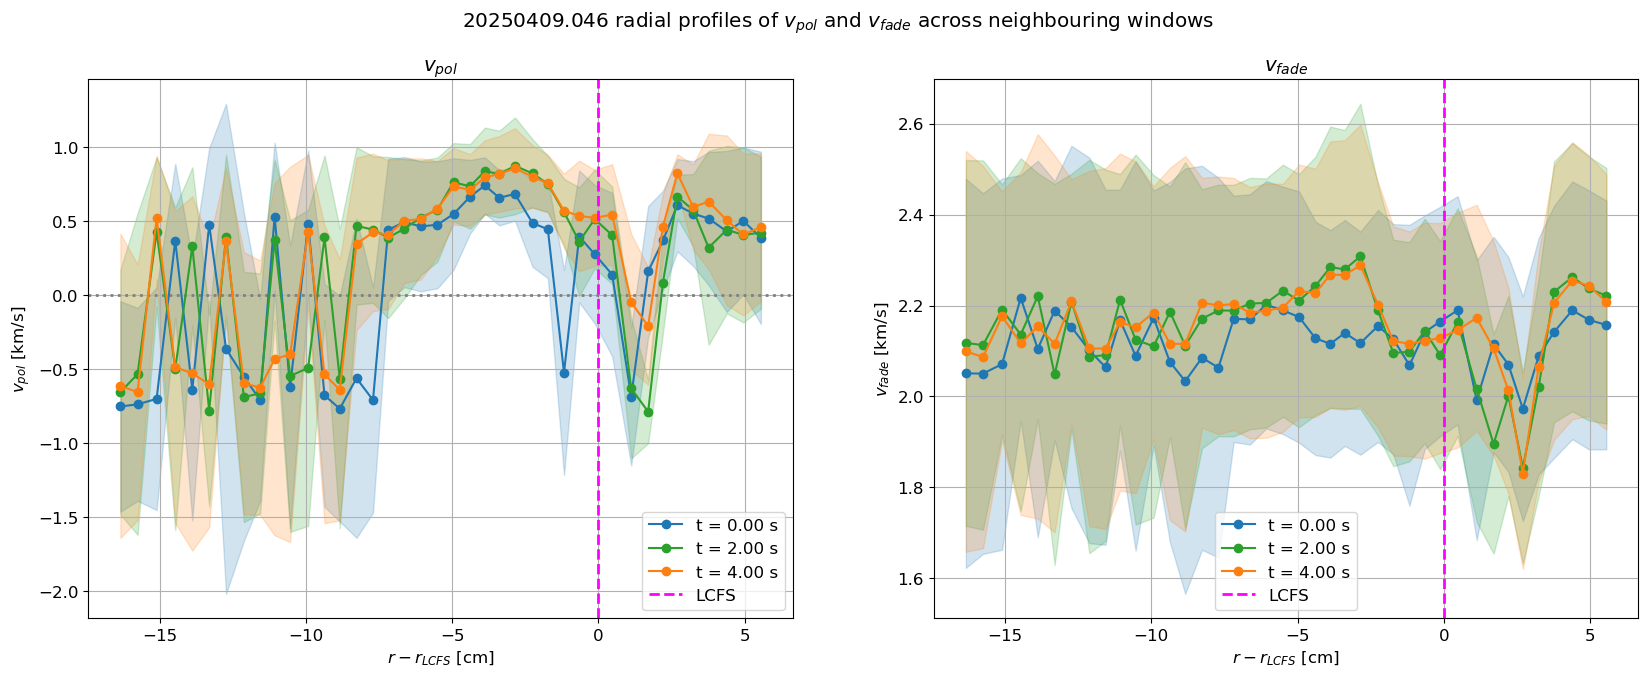

In [18]:
time_slices = [max(time_slice_idx - 20, 0), time_slice_idx, min(time_slice_idx + 20, len(times) - 1)]
colors = ['tab:blue', 'tab:green', 'tab:orange']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (20, 7), sharex = True)

ax1.set_title('$v_{pol}$')
ax2.set_title('$v_{fade}$')
ax1.set_ylabel('$v_{pol}$ [km/s]')
ax2.set_ylabel('$v_{fade}$ [km/s]')
ax1.set_xlabel('$r - r_{LCFS}$ [cm]')
ax2.set_xlabel('$r - r_{LCFS}$ [cm]')

ax1.axhline(0, lw = 2, ls = 'dotted', color = 'grey')

for (i, tidx) in enumerate(time_slices):

    mask_v = ~np.isnan(vpol_filtered[tidx])
    mask_f = ~np.isnan(vfade_filtered[tidx])

    ax1.plot(r_rel[mask_v], vpol_filtered[tidx, mask_v], marker = 'o', label = f't = {times[tidx]:.2f} s', color = colors[i])
    ax1.fill_between(r_rel[mask_v],
                      vpol_filtered[tidx, mask_v] - np.abs(vpol_err_filtered[tidx, mask_v]),
                      vpol_filtered[tidx, mask_v] + np.abs(vpol_err_filtered[tidx, mask_v]),
                      color = colors[i], alpha = 0.2)

    ax2.plot(r_rel[mask_f], vfade_filtered[tidx, mask_f], marker = 'o', label = f't = {times[tidx]:.2f} s', color = colors[i])
    ax2.fill_between(r_rel[mask_f],
                      vfade_filtered[tidx, mask_f] - np.abs(vfade_err_filtered[tidx, mask_f]),
                      vfade_filtered[tidx, mask_f] + np.abs(vfade_err_filtered[tidx, mask_f]),
                      color = colors[i], alpha = 0.2)

for a in (ax1, ax2):
    a.axvline(0, c = 'magenta', ls = '--', lw = 2, label = 'LCFS')
    a.grid()
    a.legend()

plt.suptitle(f'{exp_id} radial profiles of $v_{{pol}}$ and $v_{{fade}}$ across neighbouring windows')
# plt.savefig(f'../plots/{exp_id}/{exp_id}_vpol_vfade_radial_slices_tseries.pdf')